In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

In [2]:
data = {
    'X': [1, 2, 3, 4, 5, 6, 7, 8, 9],
    'Y': [5, 7, 9, 11, 13, 15, 17, 19, 21]
}

df = pd.DataFrame(data)

print(df)

   X   Y
0  1   5
1  2   7
2  3   9
3  4  11
4  5  13
5  6  15
6  7  17
7  8  19
8  9  21


In [3]:
X = df[['X']]
y = df['Y']

In [4]:
ols = LinearRegression()

ols.fit(X, y)

y_pred_ols = ols.predict(X)

print("OLS Regression")
print("Intercept:", ols.intercept_)
print("Coefficient:", ols.coef_[0])
print("R2 Score:", r2_score(y, y_pred_ols))
print("MSE:", mean_squared_error(y, y_pred_ols))

OLS Regression
Intercept: 2.9999999999999982
Coefficient: 2.0000000000000004
R2 Score: 1.0
MSE: 7.888609052210118e-31


In [5]:
ridge = Ridge(alpha=1.0)

ridge.fit(X, y)

y_pred_ridge = ridge.predict(X)

print("Ridge Regression")
print("Intercept:", ridge.intercept_)
print("Coefficient:", ridge.coef_[0])
print("R2 Score:", r2_score(y, y_pred_ridge))
print("MSE:", mean_squared_error(y, y_pred_ridge))

Ridge Regression
Intercept: 3.163934426229508
Coefficient: 1.9672131147540983
R2 Score: 0.999731255038968
MSE: 0.007166532294186135


In [6]:
lasso = Lasso(alpha=0.1)

lasso.fit(X, y)

y_pred_lasso = lasso.predict(X)

print("Lasso Regression")
print("Intercept:", lasso.intercept_)
print("Coefficient:", lasso.coef_[0])
print("R2 Score:", r2_score(y, y_pred_lasso))
print("MSE:", mean_squared_error(y, y_pred_lasso))

Lasso Regression
Intercept: 3.075000000000001
Coefficient: 1.9849999999999999
R2 Score: 0.99994375
MSE: 0.0015000000000000753


In [7]:
results = pd.DataFrame({
    'Actual Y': y,
    'OLS Prediction': y_pred_ols,
    'Ridge Prediction': y_pred_ridge,
    'Lasso Prediction': y_pred_lasso
})

print(results)

   Actual Y  OLS Prediction  Ridge Prediction  Lasso Prediction
0         5             5.0          5.131148             5.060
1         7             7.0          7.098361             7.045
2         9             9.0          9.065574             9.030
3        11            11.0         11.032787            11.015
4        13            13.0         13.000000            13.000
5        15            15.0         14.967213            14.985
6        17            17.0         16.934426            16.970
7        19            19.0         18.901639            18.955
8        21            21.0         20.868852            20.940


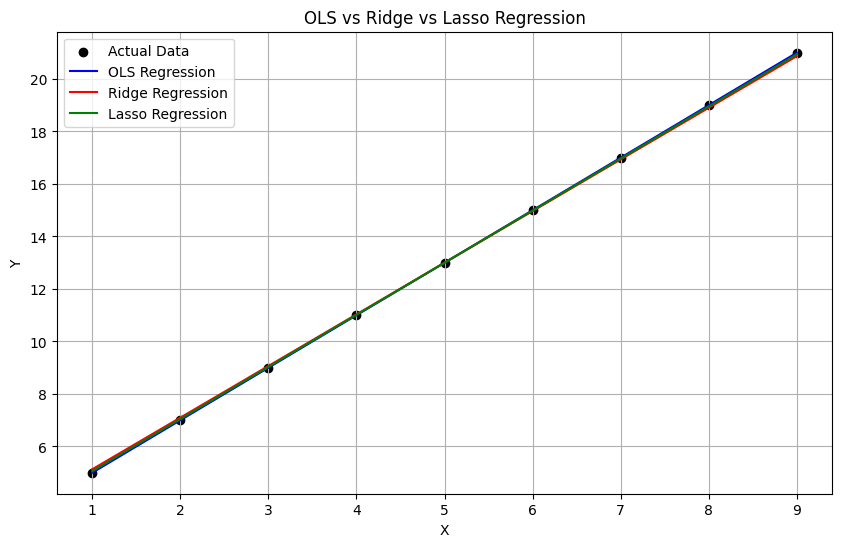

In [8]:
plt.figure(figsize=(10, 6))

plt.scatter(X, y, color='black', label='Actual Data')

plt.plot(X, y_pred_ols, color='blue', label='OLS Regression')
plt.plot(X, y_pred_ridge, color='red', label='Ridge Regression')
plt.plot(X, y_pred_lasso, color='green', label='Lasso Regression')

plt.xlabel('X')
plt.ylabel('Y')
plt.title('OLS vs Ridge vs Lasso Regression')

plt.legend()
plt.grid(True)
plt.show()